What is Data Visualization?

Data visualization is the graphical representation of data to communicate patterns, trends, relationships, and insights effectively.

Instead of looking at a table like this:


| Department | Average CGPA |
| ---------- | ------------ |
| CSE        | 8.2          |
| ECE        | 7.8          |
| IT         | 8.5          |

A bar chart immediately highlights that IT students have the highest average CGPA.

Visualization helps us:

Understand large datasets quickly.

Identify trends.

Detect outliers.

Compare groups.

Discover hidden relationships.

Support business decisions.

Matplotlib vs Seaborn
Matplotlib

Basic plotting library

Highly customizable

Good for simple charts

Seaborn

Built on Matplotlib

More attractive default styles

Easier statistical plots

Better integration with Pandas

| Chart        | Data Type               | Used For                 |
| ------------ | ----------------------- | ------------------------ |
| Histogram    | Numerical               | Distribution             |
| Boxplot      | Numerical               | Outliers & Spread        |
| Countplot    | Categorical             | Frequency Count          |
| Bar Chart    | Categorical + Numerical | Comparison               |
| Pie Chart    | Categorical             | Percentage               |
| Line Chart   | Time Series             | Trend                    |
| Scatter Plot | Numerical + Numerical   | Relationship             |
| Heatmap      | Numerical               | Correlation              |
| Pair Plot    | Multiple Numerical      | Multiple Relationships   |
| Violin Plot  | Numerical + Category    | Distribution Comparison  |
| KDE Plot     | Numerical               | Probability Distribution |
| Area Chart   | Time Series             | Cumulative Trend         |


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/student_dataset.csv")

In [ ]:
df = df.drop_duplicates()

df["Gender"] = df["Gender"].str.title()
df["Department"] = df["Department"].str.upper()
df["Placement_Status"] = df["Placement_Status"].str.title()

In [ ]:
df.head()

,Student_ID,Name,Gender,Age,Department,Semester,CGPA,Attendance,Placement_Status,City,Hostel,Family_Income,Backlogs,Study_Hours,Internship
0,1001,Simran Sharma,Female,19.0,ECE,3,8.67,94.0,Placed,Ludhiana,No,266653,0,1.7,Yes
1,1002,Muskan Arora,Male,22.0,ECE,7,6.45,97.0,Not Placed,Jalandhar,Yes,534829,3,3.4,Yes
2,1003,Rohit Patel,Male,18.0,ME,2,7.04,82.0,Not Placed,Jalandhar,Yes,1163483,4,1.9,No
3,1004,Rahul Joshi,Female,24.0,EEE,6,7.98,64.0,Not Placed,Delhi,Yes,806890,0,7.0,Yes
4,1005,Riya Gupta,Female,23.0,IT,3,7.09,73.0,Not Placed,Jalandhar,Yes,1477440,1,4.7,Yes


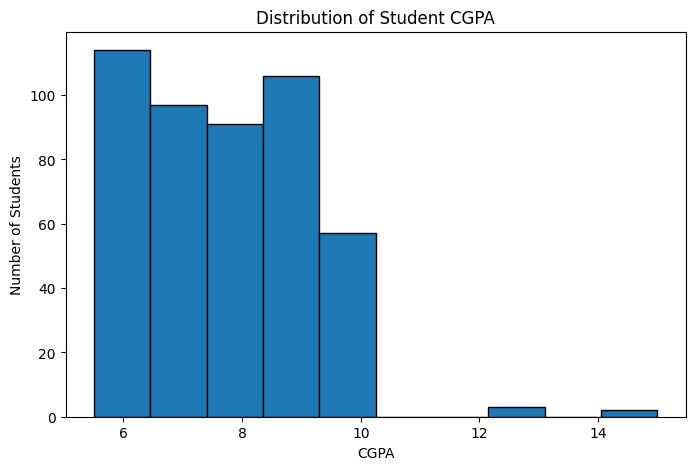

In [ ]:
# plt: alias name for Matplotlib pyplot module
# figure(): Creates a new plotting canvas (figure), its like a blank page where the graph will be drawn
# figsize(): it specifies the width and height of figure (width,height) in inches
# hist(): to create the histogram
# Selects the CGPA column from the DataFrame.
# dropna(): Removes all missing (NaN) values before plotting.
# bins: Divides the data into 10 intervals (groups).
# e.g. 5.0 to 10.0 is range it converts into 10 interval
# 5.0 to 5.5, 5.5 to 6.0 and so on
# edgecolor: Adds a black border around every bar, it can be blue, red, green
# title: Adds a title at the top of the graph.
# xlabel(): Labels the X-axis.
# ylabel(): Labels the y-axis
# show(): Displays the graph.

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))

plt.hist(df["CGPA"].dropna(),
         bins=10,
         edgecolor="black")

plt.title("Distribution of Student CGPA")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")

plt.show()

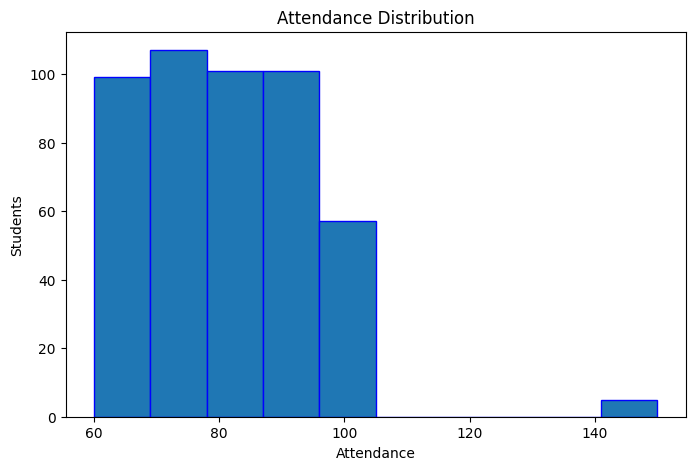

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["Attendance"].dropna(),
         bins=10,
         edgecolor="blue")

plt.title("Attendance Distribution")
plt.xlabel("Attendance")
plt.ylabel("Students")

plt.show()

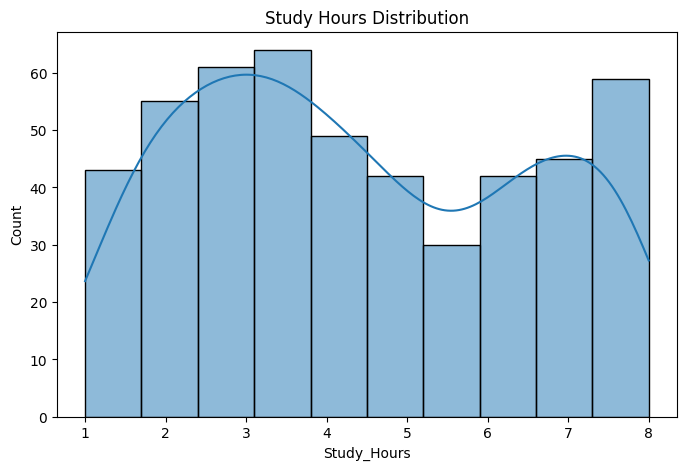

In [ ]:
# KDE: The smooth curve (Kernel Density Estimate) gives a continuous estimate
#of the data distribution, making it easier to see where values are concentrated.
plt.figure(figsize=(8,5))

sns.histplot(
    df["Study_Hours"],
    kde=True,
    bins=10
)

plt.title("Study Hours Distribution")

plt.show()

Why Boxplots?

Boxplots summarize data using:

Minimum

First Quartile (Q1)

Median (Q2)

Third Quartile (Q3)

Maximum

Outliers

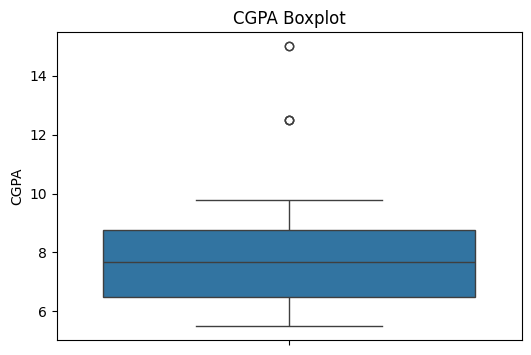

In [ ]:
# Middle line = Median
# Box = Middle 50% of values
# Dots outside whiskers = Outliers

plt.figure(figsize=(6,4))

sns.boxplot(y=df["CGPA"])

plt.title("CGPA Boxplot")

plt.show()

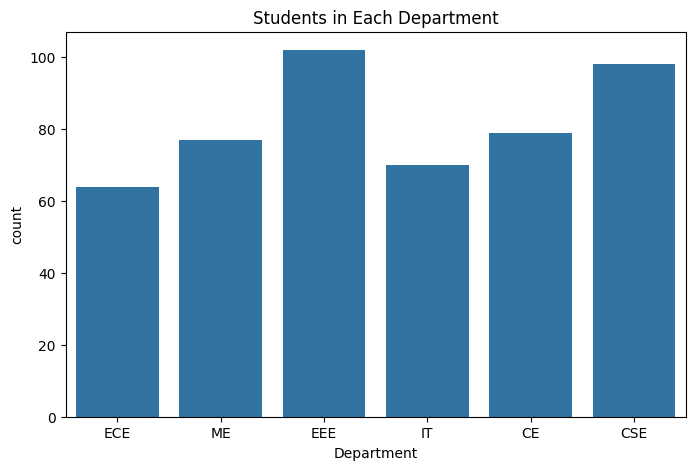

In [ ]:
# Count Plots (Categorical Data)

plt.figure(figsize=(8,5))

sns.countplot(data=df,
              x="Department")

plt.title("Students in Each Department")

plt.show()

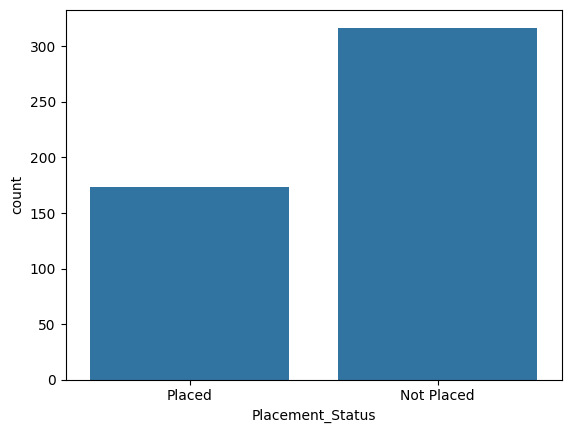

In [ ]:
sns.countplot(
    data=df,
    x="Placement_Status"
)

plt.show()

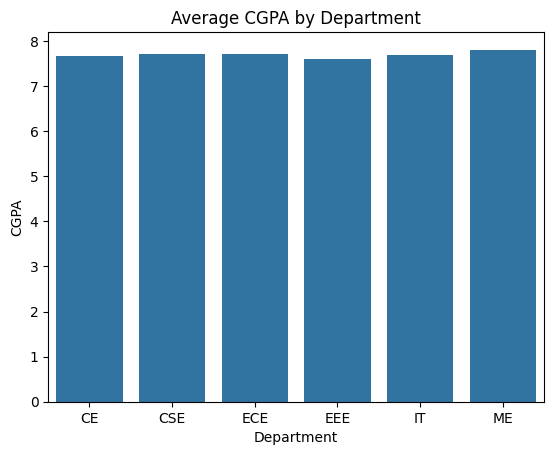

In [ ]:
# Bar Plots (Aggregated Data)

dept_cgpa = df.groupby("Department")["CGPA"].mean().reset_index()

sns.barplot(
    data=dept_cgpa,
    x="Department",
    y="CGPA"
)

plt.title("Average CGPA by Department")

plt.show()

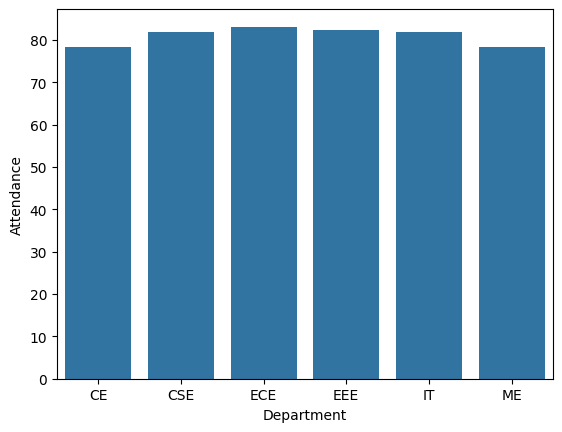

In [ ]:
dept_att = df.groupby("Department")["Attendance"].mean().reset_index()

sns.barplot(
    data=dept_att,
    x="Department",
    y="Attendance"
)

plt.show()

<Axes: ylabel='count'>

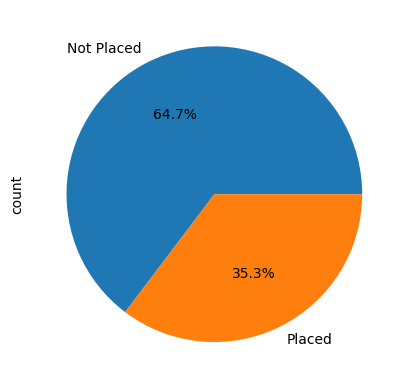

In [ ]:
# autopct stands for automatic percentage
# % Starts the formatting instruction.
# 1 means Minimum width of the displayed number.
# .1 Show 1 digit after the decimal point.
# f Display the value as a floating-point (decimal) number.
# %% Displays the % symbol. If you use only one %, Python treats it as part of the formatting syntax

df["Placement_Status"].value_counts().plot(kind="pie",autopct="%1.1f%%")

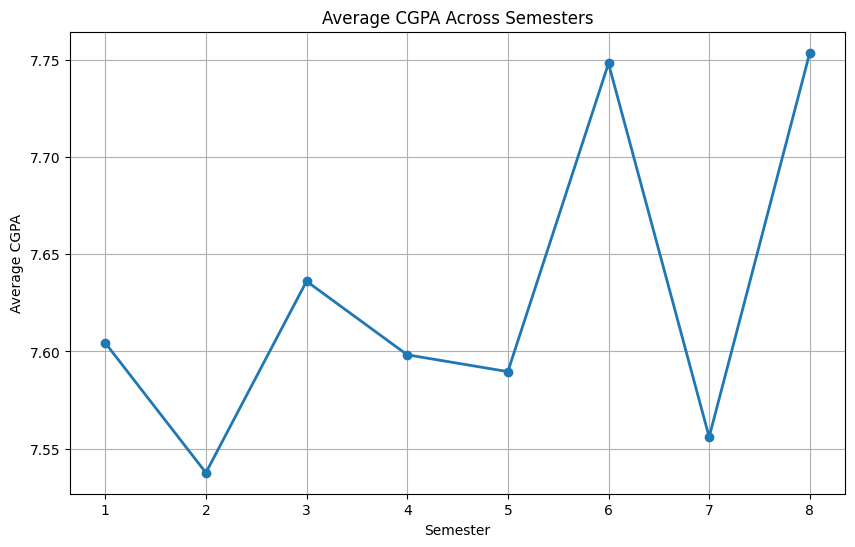

In [ ]:
# Calculate average CGPA by semester
semester_cgpa = df.groupby("Semester")["CGPA"].mean()

# Plot
plt.figure(figsize=(10,6))

plt.plot(
    semester_cgpa.index,
    semester_cgpa.values,
    marker='o',
    linewidth=2,
    linestyle='-'
)

plt.title("Average CGPA Across Semesters")
plt.xlabel("Semester")
plt.ylabel("Average CGPA")
plt.xticks(range(1,9))
plt.grid(True)

plt.show()

A Violin Plot combines the features of a:

Boxplot (Median, Quartiles)
Distribution Plot (KDE)

It not only shows the summary statistics but also how the data is distributed.

in this:

x: specifies what should appear on the X-axis.

y: specifies what should appear on the y-axis.

data- df: informs Seaborn where to get the data.

Output:
Wide Region: Many students have CGPA in this range.

Narrow Region: Few students have CGPA in this range.

Long Violin: CGPA values vary greatly.

Short Violin: Students have similar CGPA.


<Axes: xlabel='Department', ylabel='CGPA'>

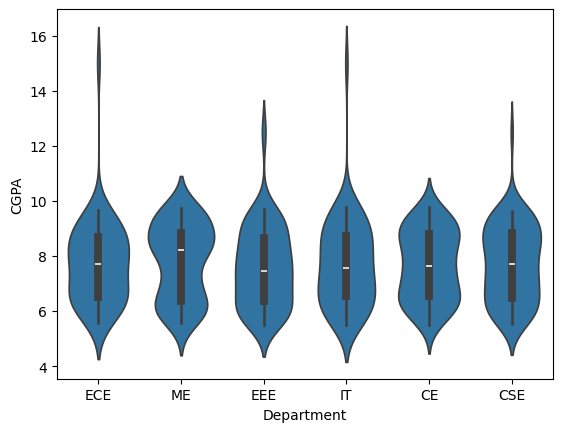

In [ ]:
# Useful when comparing distributions across categories.
sns.violinplot(
x="Department",
y="CGPA",
data=df
)

Scatter Plots (Relationships)

What is a Scatter Plot?

Shows the relationship between two numerical variables.

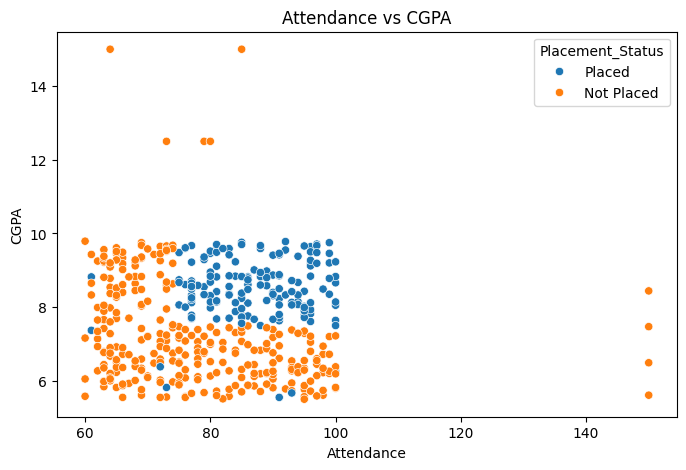

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="CGPA",
    hue="Placement_Status"
)

plt.title("Attendance vs CGPA")

plt.show()

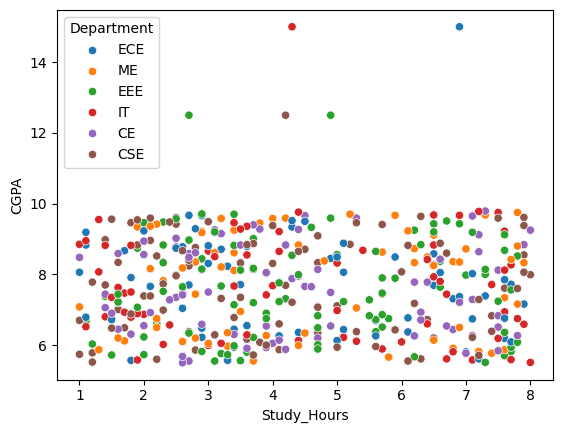

In [ ]:
sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="CGPA",
    hue="Department"
)

plt.show()

Correlation

What is Correlation?

Correlation measures the strength and direction of the relationship between numerical variables.

Correlation coefficient ranges from:

| Value | Meaning                      |
| ----- | ---------------------------- |
| +1    | Perfect positive correlation |
| 0     | No correlation               |
| -1    | Perfect negative correlation |




| Correlation Value | Interpretation                |
| ----------------- | ----------------------------- |
| +1                | Perfect positive correlation  |
| +0.7 to +0.9      | Strong positive correlation   |
| +0.3 to +0.7      | Moderate positive correlation |
| 0                 | No relationship               |
| -0.3 to -0.7      | Moderate negative correlation |
| -0.7 to -1        | Strong negative correlation   |
| -1                | Perfect negative correlation  |


Strong Positive Correlation (+0.7 to +1)
Meaning

As one variable increases, the other variable also tends to increase.

Example

Attendance (%)	CGPA

70	6.8

80	7.5

90	8.6

95	9.2

Correlation:

Attendance ↔ CGPA = +0.85
Interpretation

Students with higher attendance generally achieve higher CGPA.

What Do We Do?

Identify attendance as an important factor.
Encourage regular attendance.
Build prediction models using attendance.
Monitor students with low attendance for academic support.

Decision

"Increasing attendance may help improve academic performance."

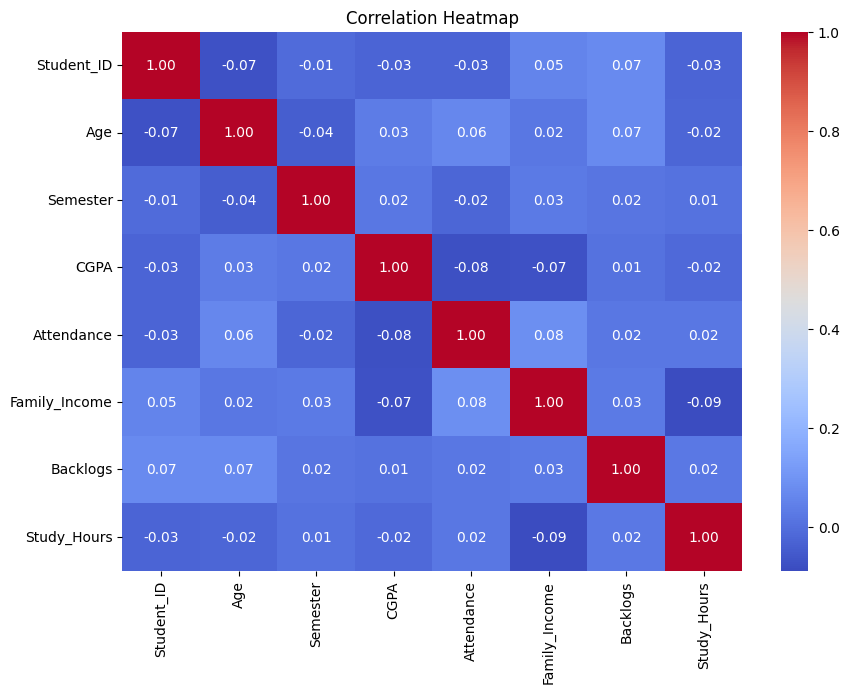

In [ ]:
corr = df.select_dtypes(include="number").corr()

corr

plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

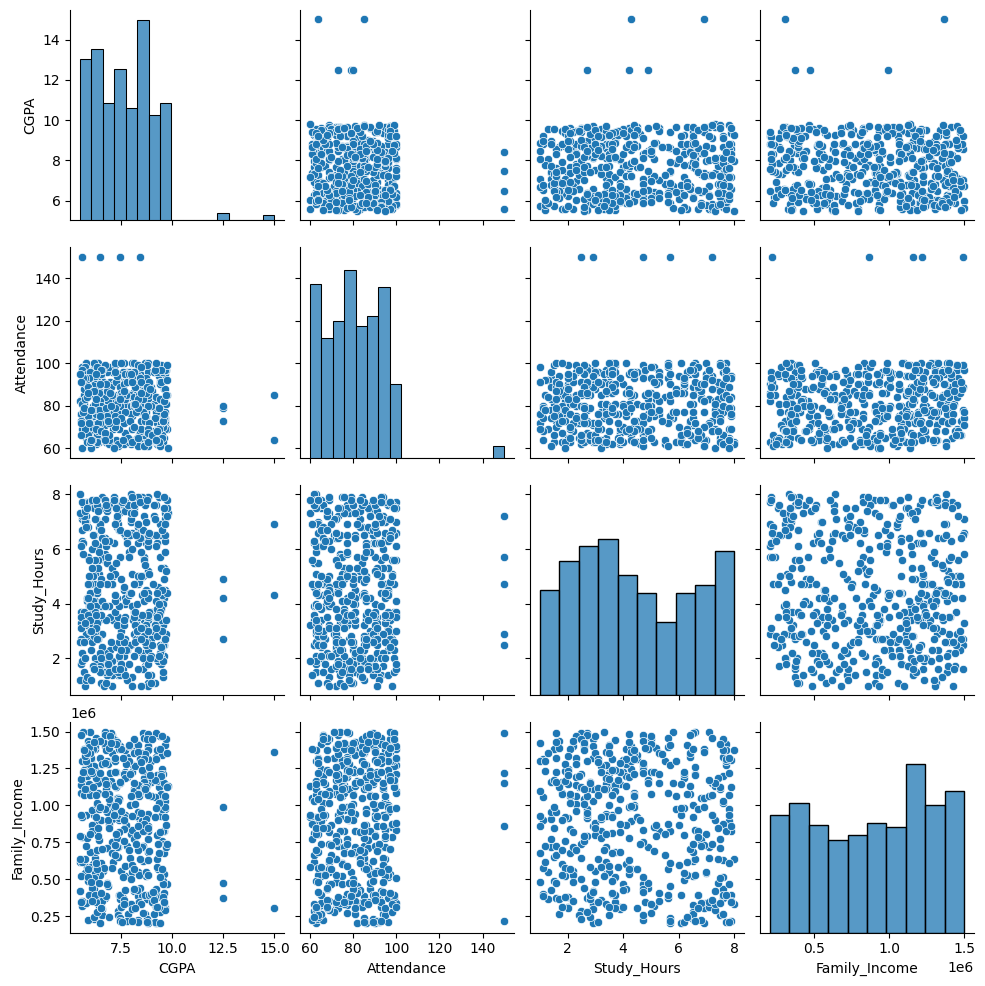

In [ ]:
sns.pairplot(
    df[["CGPA","Attendance","Study_Hours","Family_Income"]]
)

plt.show()

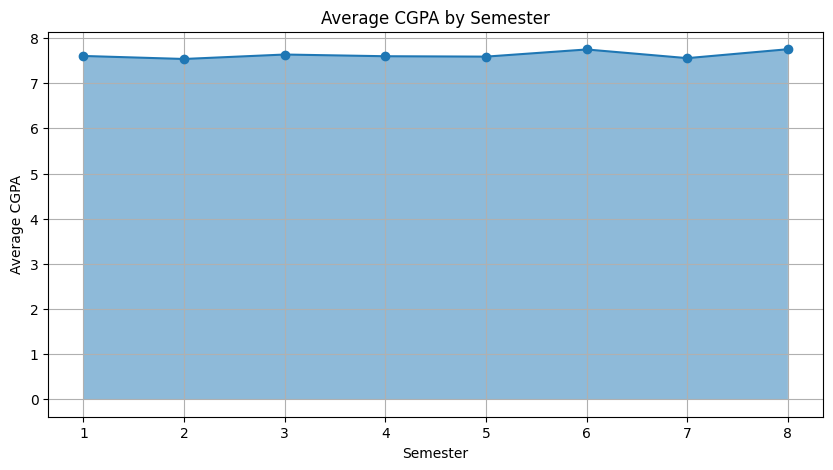

In [ ]:
# alpha is a transparency parameter in Matplotlib. It controls how transparent (or opaque) the filled area, line, bar, or marker appears.

# Remove invalid CGPA values
df = df[(df["CGPA"] >= 0) & (df["CGPA"] <= 10)]

# Calculate Average CGPA Semester-wise
semester_cgpa = df.groupby("Semester")["CGPA"].mean()

# Create Area Chart
plt.figure(figsize=(10,5))

plt.fill_between(
    semester_cgpa.index,
    semester_cgpa.values,
    alpha=0.5
)

plt.plot(
    semester_cgpa.index,
    semester_cgpa.values,
    marker='o'
)

plt.title("Average CGPA by Semester")
plt.xlabel("Semester")
plt.ylabel("Average CGPA")

plt.grid(True)

plt.show()